In [3]:
%pip install pandas numpy matplotlib seaborn

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl (9.8 MB)
Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl (12.7 MB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 3.7 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.5 MB 3.9 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 4.2 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 4.5 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 4.7 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.5 MB 4.8 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 4.8 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 4.8 MB/s eta 0:0

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:

import pandas as pd

df = pd.read_csv("../data/netflix_titles.csv")

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset loaded successfully!
Total Rows: 8807
Total Columns: 12


In [2]:

df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:

# 1. Dataset ke columns aur data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [4]:

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing Values", ascending=False
)

display(missing_report)


,Missing Values,Missing Percentage
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


In [5]:

print("Total duplicate rows:", df.duplicated().sum())
print("Total unique titles:", df["title"].nunique())
print("Total records:", len(df))


Total duplicate rows: 0
Total unique titles: 8807
Total records: 8807


In [6]:

# Create a separate copy so original data remains unchanged
clean_df = df.copy()

# Remove extra spaces from column names
clean_df.columns = clean_df.columns.str.strip()

# Remove duplicate rows, if any
before = len(clean_df)
clean_df = clean_df.drop_duplicates()
after = len(clean_df)

print("Duplicate rows removed:", before - after)
print("Rows after cleaning:", after)


Duplicate rows removed: 0
Rows after cleaning: 8807


In [7]:

# Fill missing text values without inventing information
text_columns = ["director", "cast", "country", "rating"]

for col in text_columns:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna("Unknown")

# Check missing values after cleaning
display(
    clean_df.isnull().sum()
    .to_frame(name="Missing Values After Cleaning")
)


,Missing Values After Cleaning
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,3


In [8]:

# Convert date_added into proper date format
clean_df["date_added"] = pd.to_datetime(
    clean_df["date_added"].astype("string").str.strip(),
    format="%B %d, %Y",
    errors="coerce"
)

# Extract year in which content was added
clean_df["year_added"] = clean_df["date_added"].dt.year

# Extract numeric duration
clean_df["duration_value"] = pd.to_numeric(
    clean_df["duration"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Extract duration unit: min or Season
clean_df["duration_unit"] = (
    clean_df["duration"].astype("string").str.extract(r"([A-Za-z]+)")[0]
)

display(
    clean_df[[
        "title", "type", "date_added",
        "year_added", "duration",
        "duration_value", "duration_unit"
    ]].head(10)
)


,title,type,date_added,year_added,duration,duration_value,duration_unit
0,Dick Johnson Is Dead,Movie,2021-09-25,2021.0,90 min,90,min
1,Blood & Water,TV Show,2021-09-24,2021.0,2 Seasons,2,Seasons
2,Ganglands,TV Show,2021-09-24,2021.0,1 Season,1,Season
3,Jailbirds New Orleans,TV Show,2021-09-24,2021.0,1 Season,1,Season
4,Kota Factory,TV Show,2021-09-24,2021.0,2 Seasons,2,Seasons
5,Midnight Mass,TV Show,2021-09-24,2021.0,1 Season,1,Season
6,My Little Pony: A New Generation,Movie,2021-09-24,2021.0,91 min,91,min
7,Sankofa,Movie,2021-09-24,2021.0,125 min,125,min
8,The Great British Baking Show,TV Show,2021-09-24,2021.0,9 Seasons,9,Seasons
9,The Starling,Movie,2021-09-24,2021.0,104 min,104,min


In [9]:

print("FINAL DATA QUALITY REPORT")
print("-" * 35)
print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Total columns:", len(clean_df.columns))
print("Remaining missing values:", clean_df.isnull().sum().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

print("\nCleaned dataset preview:")
display(clean_df.head())


FINAL DATA QUALITY REPORT
-----------------------------------
Original rows: 8807
Cleaned rows: 8807
Total columns: 15
Remaining missing values: 29
Duplicate rows: 0

Cleaned dataset preview:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,90,min
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,2,Seasons
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,1,Season
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,1,Season
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,2,Seasons


In [10]:

# Count Movies and TV Shows
content_counts = clean_df["type"].value_counts()

print("CONTENT TYPE ANALYSIS")
print("-" * 30)

for content_type, count in content_counts.items():
    percentage = count / len(clean_df) * 100
    print(f"{content_type}: {count} titles ({percentage:.2f}%)")


CONTENT TYPE ANALYSIS
------------------------------
Movie: 6131 titles (69.62%)
TV Show: 2676 titles (30.38%)


In [11]:

# Content grouped by release year
release_year_counts = (
    clean_df.groupby("release_year")["show_id"]
    .count()
    .sort_values(ascending=False)
)

print("Top 10 release years by number of titles:")
display(
    release_year_counts.head(10).to_frame("Total Titles")
)


Top 10 release years by number of titles:


,Total Titles
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
2021,592
2015,560
2014,352
2013,288


In [12]:

# Split multiple genres into separate rows
genre_counts = (
    clean_df.assign(
        genre=clean_df["listed_in"].str.split(", ")
    )
    .explode("genre")
    .groupby("genre")["show_id"]
    .count()
    .sort_values(ascending=False)
)

print("TOP 10 GENRES")
display(genre_counts.head(10).to_frame("Total Titles"))


TOP 10 GENRES


,Total Titles
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


In [13]:

# Split countries because one title can have multiple countries
country_counts = (
    clean_df.assign(
        country_item=clean_df["country"].str.split(", ")
    )
    .explode("country_item")
)

country_counts = country_counts[
    country_counts["country_item"] != "Unknown"
]

country_counts = (
    country_counts.groupby("country_item")["show_id"]
    .count()
    .sort_values(ascending=False)
)

print("TOP 10 COUNTRIES")
display(country_counts.head(10).to_frame("Total Titles"))


TOP 10 COUNTRIES


,Total Titles
country_item,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


In [14]:

from pathlib import Path

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready:", OUTPUT_DIR.resolve())


Output folder ready: C:\Users\acer\Desktop\OTT-Streaming-Content-Trend-Analysis\outputs


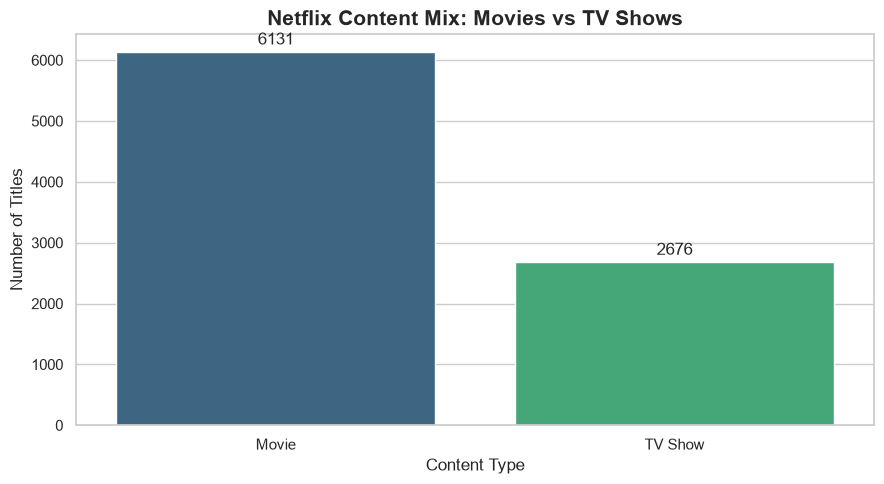

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

type_counts = clean_df["type"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    hue=type_counts.index,
    palette="viridis",
    legend=False,
    ax=ax
)

ax.set_title("Netflix Content Mix: Movies vs TV Shows",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_content_type.png",
            dpi=300, bbox_inches="tight")
plt.show()


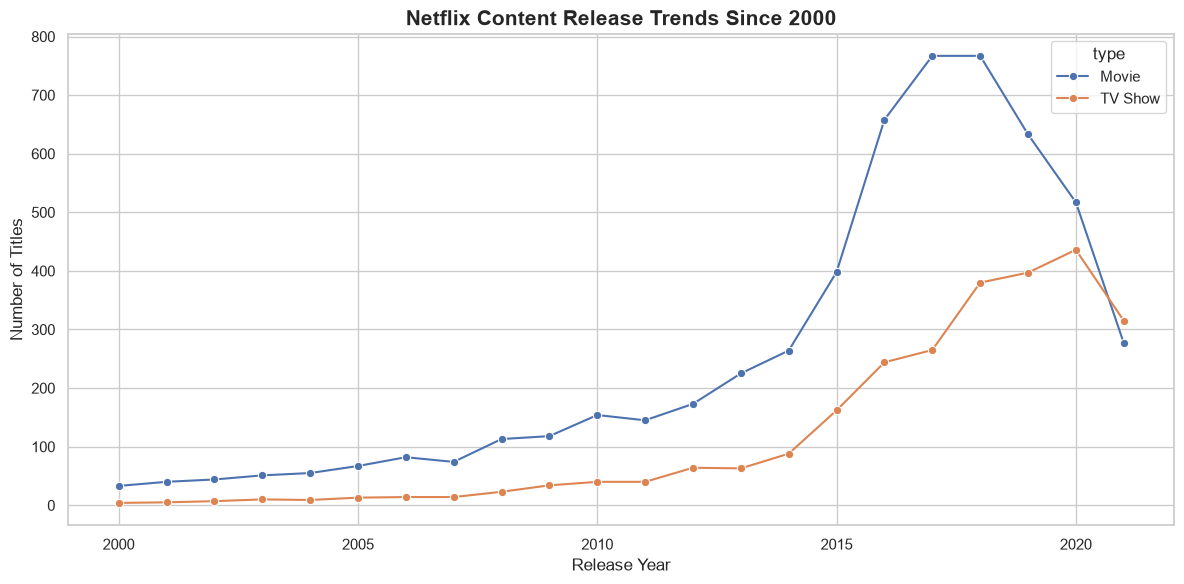

In [16]:

year_counts = (
    clean_df.groupby(["release_year", "type"])
    .size()
    .reset_index(name="Total Titles")
)

year_counts = year_counts[year_counts["release_year"] >= 2000]

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=year_counts,
    x="release_year",
    y="Total Titles",
    hue="type",
    marker="o",
    ax=ax
)

ax.set_title("Netflix Content Release Trends Since 2000",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_release_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()


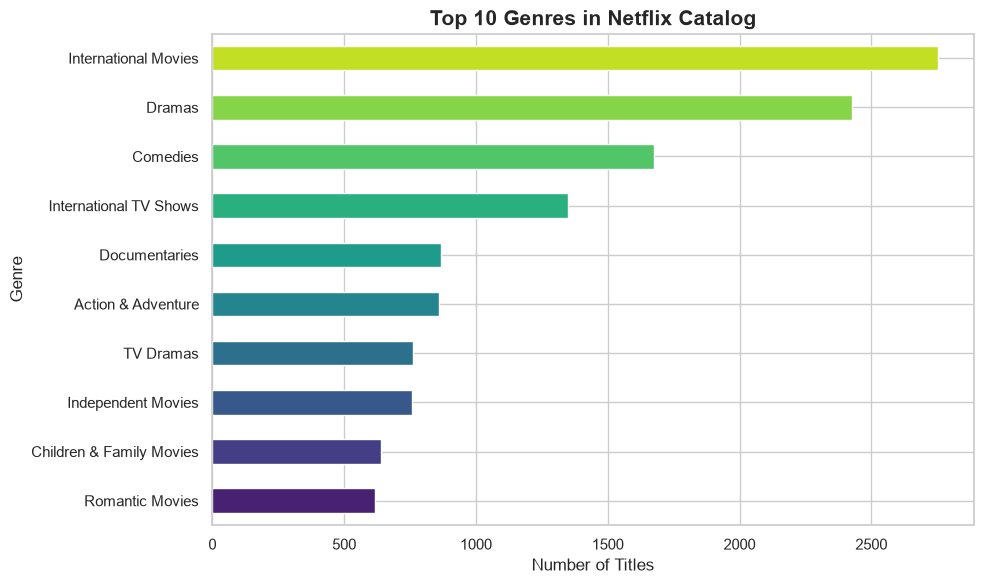

In [17]:

top_genres = genre_counts.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

top_genres.plot(kind="barh", ax=ax, color=sns.color_palette("viridis", 10))

ax.set_title("Top 10 Genres in Netflix Catalog",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Genre")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_top_genres.png",
            dpi=300, bbox_inches="tight")
plt.show()


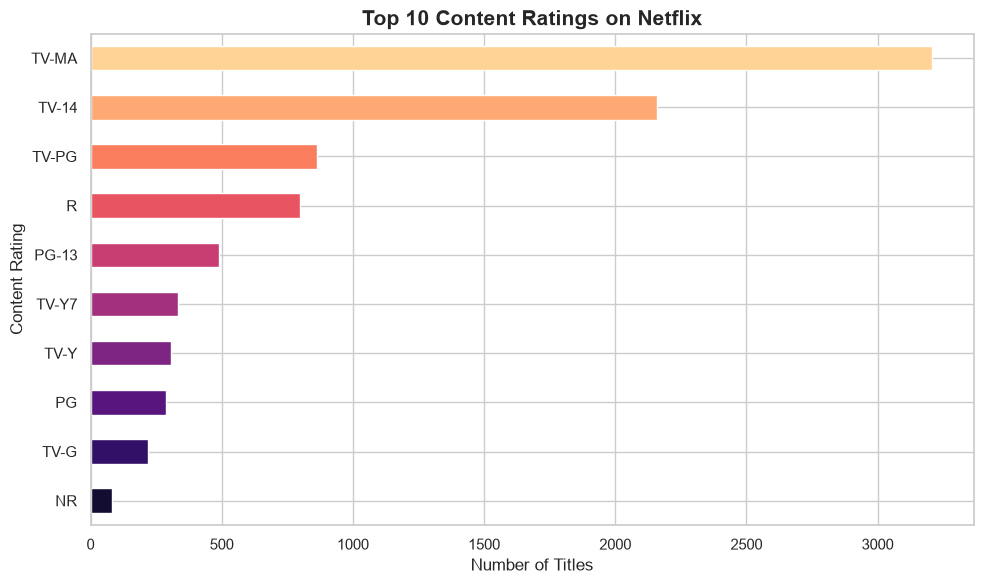

In [18]:

rating_counts = (
    clean_df["rating"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

rating_counts.plot(
    kind="barh",
    ax=ax,
    color=sns.color_palette("magma", len(rating_counts))
)

ax.set_title("Top 10 Content Ratings on Netflix",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Content Rating")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_ratings.png",
            dpi=300, bbox_inches="tight")
plt.show()


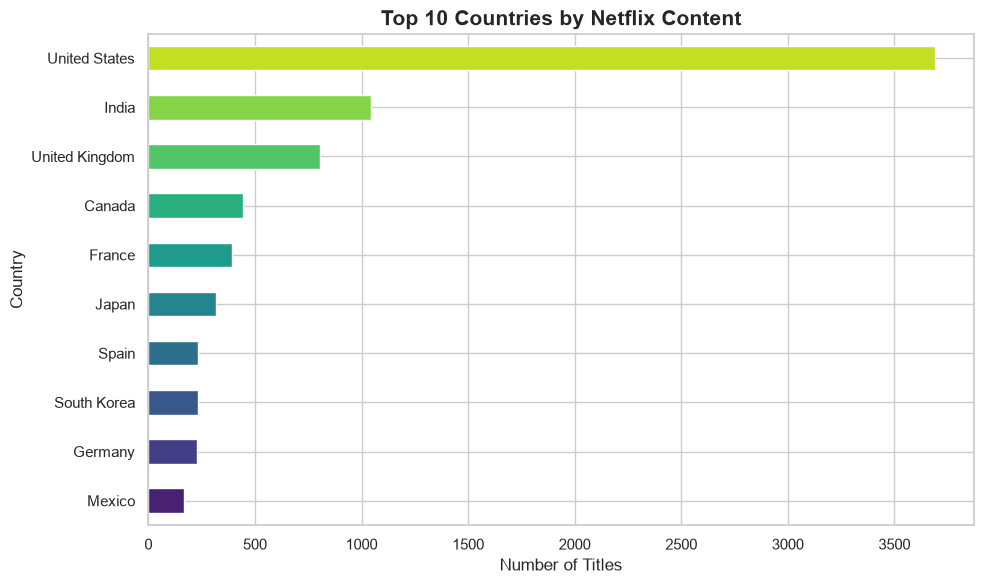

In [19]:

top_countries = country_counts.head(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

top_countries.plot(
    kind="barh",
    ax=ax,
    color=sns.color_palette("viridis", len(top_countries))
)

ax.set_title("Top 10 Countries by Netflix Content",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Country")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_top_countries.png",
            dpi=300, bbox_inches="tight")
plt.show()


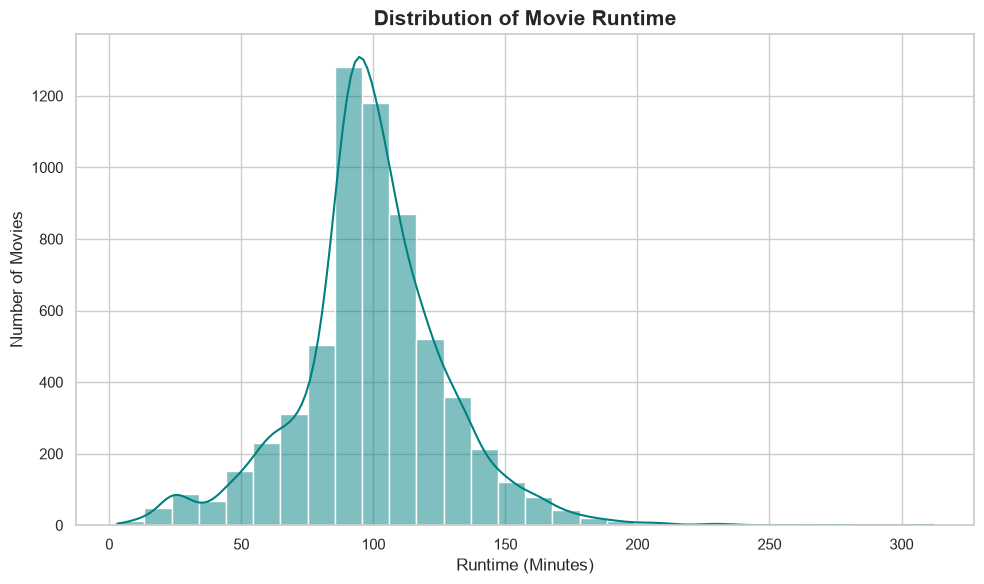

Movies analyzed: 6128
Average runtime: 99.58 minutes
Median runtime: 98.0 minutes


In [20]:

movie_duration = clean_df.loc[
    (clean_df["type"] == "Movie") &
    (clean_df["duration_unit"].str.lower() == "min"),
    "duration_value"
].dropna()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    movie_duration,
    bins=30,
    kde=True,
    ax=ax,
    color="teal"
)

ax.set_title("Distribution of Movie Runtime",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Runtime (Minutes)")
ax.set_ylabel("Number of Movies")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_duration.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Movies analyzed:", len(movie_duration))
print("Average runtime:", round(movie_duration.mean(), 2), "minutes")
print("Median runtime:", round(movie_duration.median(), 2), "minutes")


In [21]:

chart_files = sorted(OUTPUT_DIR.glob("*.png"))

print("Total charts created:", len(chart_files))

for file in chart_files:
    print("✓", file.name)


Total charts created: 6
✓ 01_content_type.png
✓ 02_release_trend.png
✓ 03_top_genres.png
✓ 04_ratings.png
✓ 05_top_countries.png
✓ 06_duration.png


In [22]:

# Generate data-backed findings from the cleaned dataset

total_titles = len(clean_df)
type_counts = clean_df["type"].value_counts()
top_genre = genre_counts.index[0]
top_country = country_counts.index[0]
top_rating = clean_df["rating"].value_counts().index[0]

print("=" * 50)
print("OTT STREAMING CONTENT — KEY FINDINGS")
print("=" * 50)

print(f"\n1. Total titles analyzed: {total_titles:,}")

print("\n2. Content Mix:")
for content_type, count in type_counts.items():
    percentage = count / total_titles * 100
    print(f"   {content_type}: {count:,} ({percentage:.2f}%)")

print(f"\n3. Most represented genre: {top_genre}")
print(f"   Titles: {genre_counts.iloc[0]:,}")

print(f"\n4. Leading country in the catalog: {top_country}")
print(f"   Titles: {country_counts.iloc[0]:,}")

print(f"\n5. Most common rating: {top_rating}")

print(f"\n6. Average movie runtime: {movie_duration.mean():.2f} minutes")
print(f"   Median movie runtime: {movie_duration.median():.2f} minutes")


OTT STREAMING CONTENT — KEY FINDINGS

1. Total titles analyzed: 8,807

2. Content Mix:
   Movie: 6,131 (69.62%)
   TV Show: 2,676 (30.38%)

3. Most represented genre: International Movies
   Titles: 2,752

4. Leading country in the catalog: United States
   Titles: 3,689

5. Most common rating: TV-MA

6. Average movie runtime: 99.58 minutes
   Median movie runtime: 98.00 minutes



## Key Findings and Business Interpretation

### 1. Content Mix
Movies account for 69.62% of the catalog, while TV Shows represent 30.38%. This indicates that movies form the larger share of the analyzed content library.

### 2. Genre Representation
International Movies is the most represented genre label, with 2,752 title entries. This highlights the importance of international content in the catalog.

### 3. Regional Contribution
The United States leads the country-level catalog count with 3,689 title entries. This provides a starting point for examining regional content representation.

### 4. Content Ratings
TV-MA is the most common content rating in the dataset. Content planning should consider audience suitability and the platform's intended audience segments.

### 5. Movie Runtime
The average movie runtime is 99.58 minutes, and the median is 98 minutes. These values provide a useful baseline for comparing runtime patterns across genres.

### Conclusion
The analysis establishes a baseline view of content type, genre representation, regional contribution, ratings, and movie runtime. Further analysis is needed before making content acquisition decisions.



## Day 2: Advanced OTT Content Analysis

This section explores genre-level content distribution, release patterns, country-level representation, and TV show season trends to identify potential content strategy opportunities.


In [23]:

# Split multi-genre entries into individual genre rows
genre_df = clean_df.assign(
    genre=clean_df["listed_in"].str.split(", ")
).explode("genre")

# Count Movies and TV Shows in each genre
genre_type_counts = (
    genre_df.groupby(["genre", "type"])
    .size()
    .unstack(fill_value=0)
)

# Display the 10 most represented genres
top_10_genres = genre_df["genre"].value_counts().head(10).index

display(
    genre_type_counts
    .loc[top_10_genres]
    .sort_values(by="Movie", ascending=True)
)


type,Movie,TV Show
genre,,
International TV Shows,0,1351
TV Dramas,0,763
Romantic Movies,616,0
Children & Family Movies,641,0
Independent Movies,756,0
Action & Adventure,859,0
Documentaries,869,0
Comedies,1674,0
Dramas,2427,0


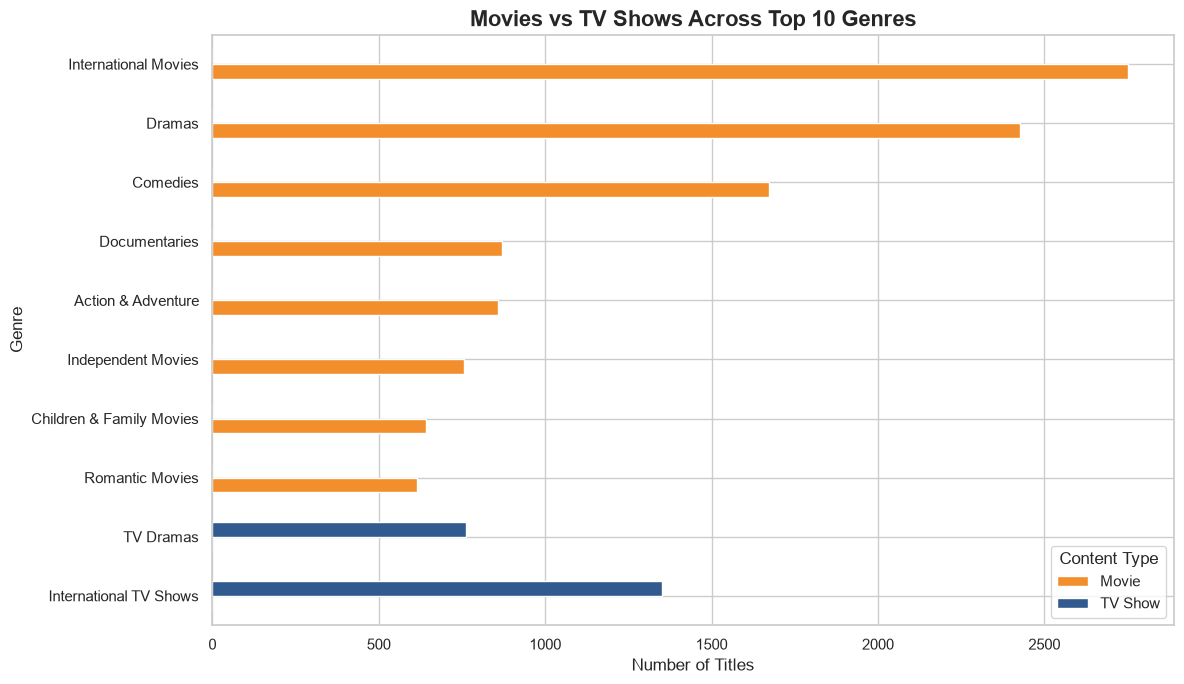

In [24]:

# Compare Movies and TV Shows across the top 10 genres

plot_data = genre_type_counts.loc[top_10_genres].sort_values(
    by="Movie", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

plot_data.plot(
    kind="barh",
    ax=ax,
    color=["#F28E2B", "#315A8E"]
)

ax.set_title(
    "Movies vs TV Shows Across Top 10 Genres",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Number of Titles")
ax.set_ylabel("Genre")
ax.legend(title="Content Type")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "07_genre_content_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [25]:

# Filter TV Shows and extract season counts
tv_seasons = clean_df.loc[
    clean_df["type"] == "TV Show",
    ["title", "duration_value", "duration_unit"]
].copy()

tv_seasons = tv_seasons[
    tv_seasons["duration_unit"].str.lower() == "season"
]

season_counts = (
    tv_seasons["duration_value"]
    .value_counts()
    .sort_index()
)

print("TV SHOW SEASON ANALYSIS")
print("TV Shows with known season counts:", len(tv_seasons))
print("Average seasons:", round(tv_seasons["duration_value"].mean(), 2))
print("Median seasons:", tv_seasons["duration_value"].median())

display(season_counts.to_frame("Number of Shows"))


TV SHOW SEASON ANALYSIS
TV Shows with known season counts: 1793
Average seasons: 1.0
Median seasons: 1.0


,Number of Shows
duration_value,
1,1793


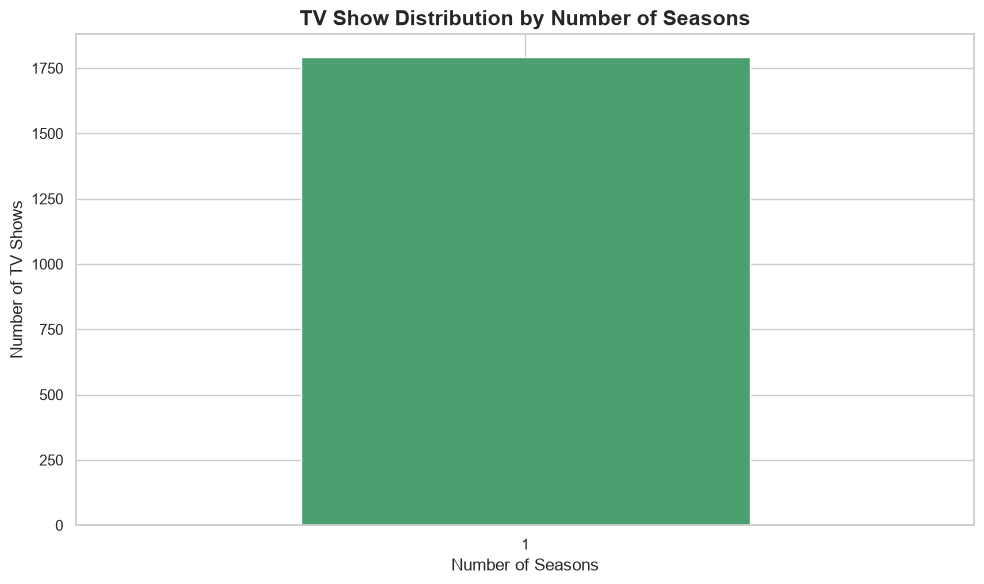

In [26]:

fig, ax = plt.subplots(figsize=(10, 6))

season_counts.plot(
    kind="bar",
    ax=ax,
    color="#4C9F70"
)

ax.set_title(
    "TV Show Distribution by Number of Seasons",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Number of Seasons")
ax.set_ylabel("Number of TV Shows")

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "08_tv_season_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## Release Trends and Content Addition Analysis

This section compares the years in which content was originally released with the years in which titles were added to the Netflix catalog. These are different measures and help explain catalog composition and acquisition patterns.


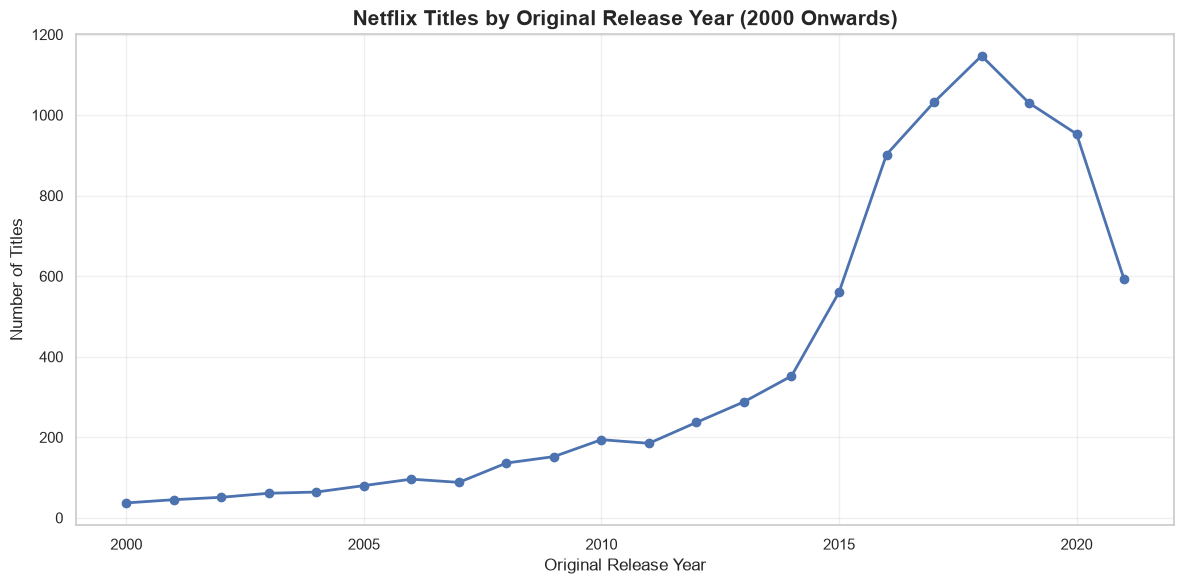

Year with the most titles in this period: 2018
Title count for that year: 1147


In [27]:

# Count titles by their original release year
release_trend = (
    clean_df.dropna(subset=["release_year"])
    .groupby("release_year")
    .size()
    .sort_index()
)

# Focus on 2000 onwards for a readable trend
recent_release_trend = release_trend.loc[
    release_trend.index >= 2000
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    recent_release_trend.index,
    recent_release_trend.values,
    marker="o",
    linewidth=2
)

ax.set_title(
    "Netflix Titles by Original Release Year (2000 Onwards)",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Original Release Year")
ax.set_ylabel("Number of Titles")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "09_release_year_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Year with the most titles in this period:",
      recent_release_trend.idxmax())
print("Title count for that year:",
      recent_release_trend.max())


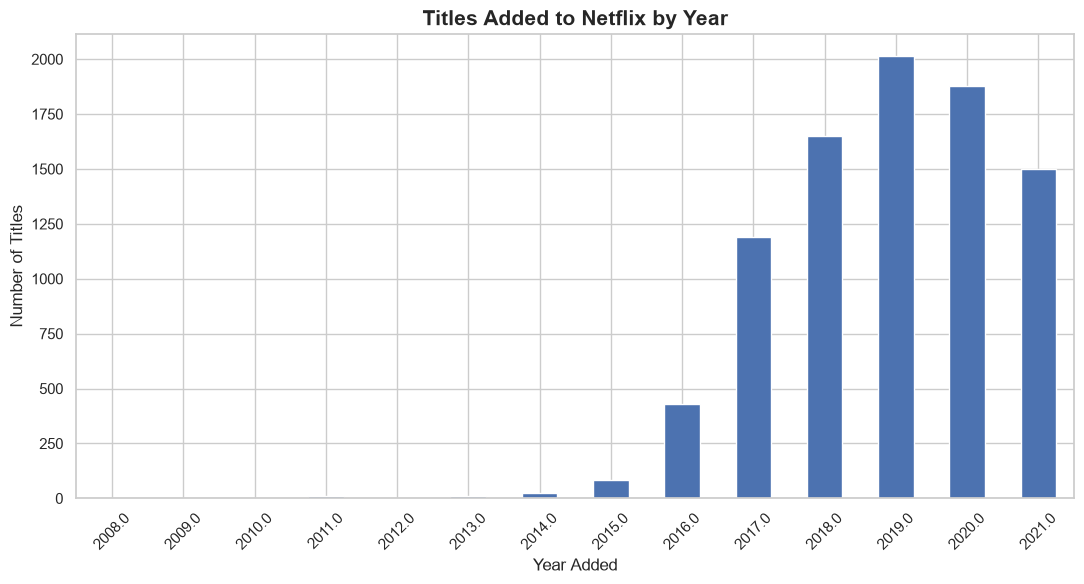

Year with the most additions: 2019.0
Titles added in that year: 2016


In [28]:

# Count titles by the year they were added to Netflix
addition_trend = (
    clean_df.dropna(subset=["year_added"])
    .groupby("year_added")
    .size()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(11, 6))

addition_trend.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Titles Added to Netflix by Year",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Year Added")
ax.set_ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "10_content_addition_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Year with the most additions:",
      addition_trend.idxmax())
print("Titles added in that year:",
      addition_trend.max())



## Country-wise Genre Analysis

This section examines the genre distribution across major content-producing countries. The goal is to understand how content categories vary by region and identify areas for further investigation.


In [30]:

# Split country and genre lists into individual rows
country_genre_df = clean_df[
    ["show_id", "country", "listed_in"]
].copy()

country_genre_df["country"] = country_genre_df["country"].str.split(", ")
country_genre_df["listed_in"] = country_genre_df["listed_in"].str.split(", ")

country_genre_df = country_genre_df.explode("country")
country_genre_df = country_genre_df.explode("listed_in")

# Exclude unknown countries
country_genre_df = country_genre_df[
    country_genre_df["country"] != "Unknown"
]

# Find top 5 countries by title count
top_5_countries = country_counts.head(5).index.tolist()

# Count titles by country and genre
country_genre_counts = (
    country_genre_df[
        country_genre_df["country"].isin(top_5_countries)
    ]
    .groupby(["country", "listed_in"])["show_id"]
    .nunique()
    .reset_index(name="Titles")
)

display(
    country_genre_counts.sort_values(
        ["country", "Titles"], ascending=[True, False]
    ).groupby("country").head(5)
)


,country,listed_in,Titles
5,Canada,Comedies,94
10,Canada,Dramas,82
3,Canada,Children & Family Movies,80
16,Canada,Kids' TV,61
14,Canada,International Movies,60
50,France,International Movies,207
46,France,Dramas,167
49,France,Independent Movies,73
41,France,Comedies,51
44,France,Documentaries,44


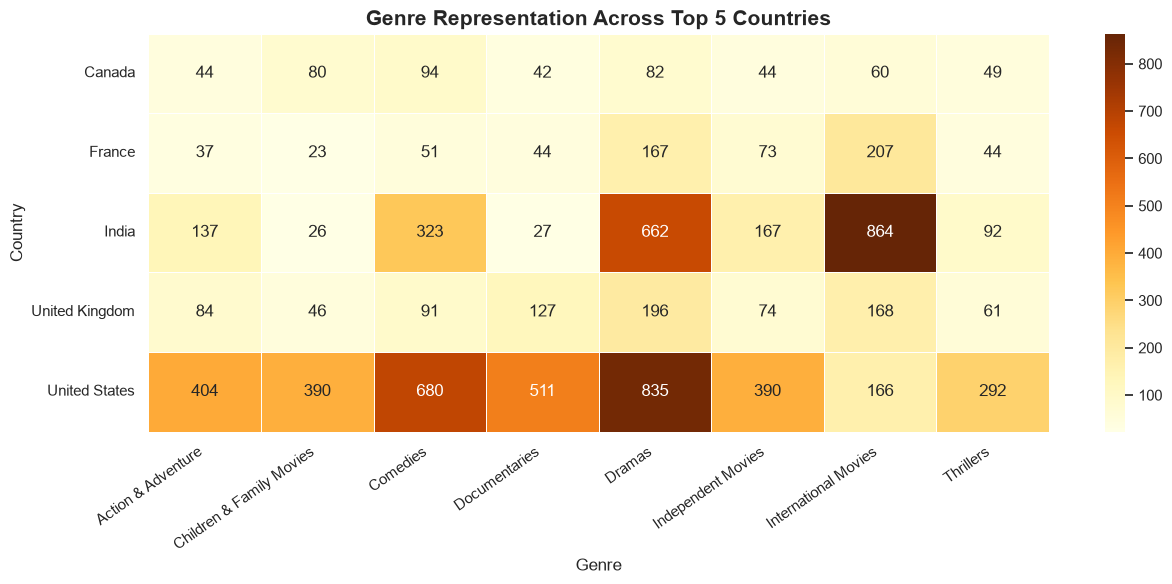

In [31]:

# Select the top 8 genres across the selected countries
top_8_genres = (
    country_genre_counts.groupby("listed_in")["Titles"]
    .sum()
    .nlargest(8)
    .index
)

heatmap_data = country_genre_counts[
    country_genre_counts["listed_in"].isin(top_8_genres)
].pivot(
    index="country",
    columns="listed_in",
    values="Titles"
).fillna(0)

fig, ax = plt.subplots(figsize=(13, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrBr",
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Genre Representation Across Top 5 Countries",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Genre")
ax.set_ylabel("Country")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "11_country_genre_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [32]:

print("Country-genre heatmap exists:",
      (OUTPUT_DIR / "11_country_genre_heatmap.png").exists())


Country-genre heatmap exists: True


In [33]:

from pathlib import Path

# Prepare report folder
REPORT_DIR = Path("../report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Calculate findings from the actual dataset
total = len(clean_df)
movies = int((clean_df["type"] == "Movie").sum())
tv_shows = int((clean_df["type"] == "TV Show").sum())

movie_pct = movies / total * 100
tv_pct = tv_shows / total * 100

top_genre_name = genre_counts.index[0]
top_genre_count = int(genre_counts.iloc[0])

top_country_name = country_counts.index[0]
top_country_count = int(country_counts.iloc[0])

top_rating_name = clean_df["rating"].value_counts().index[0]

avg_runtime = movie_duration.mean()
median_runtime = movie_duration.median()

# Create a findings report
findings = f"""
# OTT Streaming Content Trend Analysis
## Exploratory Data Analysis — Findings Summary

### 1. Dataset Overview
A total of {total:,} catalog records were analyzed after the cleaning process.

### 2. Content Mix
- Movies: {movies:,} ({movie_pct:.2f}%)
- TV Shows: {tv_shows:,} ({tv_pct:.2f}%)

Interpretation: Movies form the larger share of the analyzed catalog.

### 3. Genre Representation
- Most represented genre: {top_genre_name}
- Genre title entries: {top_genre_count:,}

Interpretation: This genre has a strong representation in the catalog.
Genre entries can overlap because a title may belong to multiple genres.

### 4. Country Representation
- Leading country: {top_country_name}
- Country title entries: {top_country_count:,}

Interpretation: This country has the highest representation in the
country-level analysis. A title may be associated with multiple countries.

### 5. Content Ratings
- Most common rating: {top_rating_name}

Interpretation: This is the most frequently recorded rating in the catalog.
Rating alone does not establish audience demand or satisfaction.

### 6. Movie Runtime
- Average runtime: {avg_runtime:.2f} minutes
- Median runtime: {median_runtime:.2f} minutes

Interpretation: The median provides a useful reference point for
comparing runtime patterns across movie categories.

### 7. Business Recommendations — To Validate
1. Review the balance between Movies and TV Shows alongside genre-level
   representation before deciding future content investments.
2. Investigate underrepresented genre-country combinations as potential
   opportunities, using audience and market data before making decisions.
3. Compare runtime and rating patterns by genre to support content planning
   and audience suitability decisions.

### Limitations
This dataset describes catalog metadata, not viewing figures, revenue,
customer satisfaction, or actual demand. Recommendations should be
validated with audience and business performance data.
"""

report_path = REPORT_DIR / "eda_findings.md"
report_path.write_text(findings.strip(), encoding="utf-8")

print("Findings report saved successfully!")
print("Location:", report_path.resolve())
print(findings)


Findings report saved successfully!
Location: C:\Users\acer\Desktop\OTT-Streaming-Content-Trend-Analysis\report\eda_findings.md

# OTT Streaming Content Trend Analysis
## Exploratory Data Analysis — Findings Summary

### 1. Dataset Overview
A total of 8,807 catalog records were analyzed after the cleaning process.

### 2. Content Mix
- Movies: 6,131 (69.62%)
- TV Shows: 2,676 (30.38%)

Interpretation: Movies form the larger share of the analyzed catalog.

### 3. Genre Representation
- Most represented genre: International Movies
- Genre title entries: 2,752

Interpretation: This genre has a strong representation in the catalog.
Genre entries can overlap because a title may belong to multiple genres.

### 4. Country Representation
- Leading country: United States
- Country title entries: 3,689

Interpretation: This country has the highest representation in the
country-level analysis. A title may be associated with multiple countries.

### 5. Content Ratings
- Most common rating: TV-MA




# Day 3: SQL Analysis

SQLite is used to store the Netflix catalog in a relational database.
SQL queries will be used to validate core aggregations such as content type,
release year, ratings, and movie duration against the Python analysis.


In [34]:

import sqlite3
from pathlib import Path

# Create database inside the project folder
DB_PATH = Path("../data/netflix_analysis.db")
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(DB_PATH)

# Import the original dataset into SQLite
sql_df = df.copy()

sql_df.to_sql(
    "netflix_titles",
    conn,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully!")
print("Database location:", DB_PATH.resolve())
print("Table name: netflix_titles")

# Verify the imported row count
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM netflix_titles",
    conn
)

display(result)


SQLite database created successfully!
Database location: C:\Users\acer\Desktop\OTT-Streaming-Content-Trend-Analysis\data\netflix_analysis.db
Table name: netflix_titles


,total_records
0,8807


In [35]:

query = """
SELECT
    type,
    COUNT(*) AS total_titles,
    ROUND(
        COUNT(*) * 100.0 / (SELECT COUNT(*) FROM netflix_titles),
        2
    ) AS percentage
FROM netflix_titles
GROUP BY type
ORDER BY total_titles DESC;
"""

sql_type_results = pd.read_sql_query(query, conn)
display(sql_type_results)


,type,total_titles,percentage
0,Movie,6131,69.62
1,TV Show,2676,30.38


In [36]:

python_counts = clean_df["type"].value_counts().sort_index()
sql_counts = (
    sql_type_results.set_index("type")["total_titles"].sort_index()
)

comparison = pd.concat(
    [
        python_counts.rename("Python Count"),
        sql_counts.rename("SQL Count")
    ],
    axis=1
)

comparison["Match"] = (
    comparison["Python Count"] == comparison["SQL Count"]
)

display(comparison)


,Python Count,SQL Count,Match
type,,,
Movie,6131,6131,True
TV Show,2676,2676,True


In [37]:

# Query 2: Content by release year
q2 = """
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
WHERE release_year IS NOT NULL
GROUP BY release_year
ORDER BY release_year DESC
LIMIT 15;
"""

display(pd.read_sql_query(q2, conn))


# Query 3: Top content ratings
q3 = """
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
WHERE rating IS NOT NULL
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;
"""

display(pd.read_sql_query(q3, conn))


# Query 4: Movie runtime distribution
q4 = """
SELECT
    CAST(REPLACE(duration, ' min', '') AS INTEGER) AS runtime_minutes,
    COUNT(*) AS total_movies
FROM netflix_titles
WHERE type = 'Movie'
  AND duration LIKE '% min'
GROUP BY runtime_minutes
ORDER BY total_movies DESC
LIMIT 10;
"""

display(pd.read_sql_query(q4, conn))


# Query 5: TV Shows by season count
q5 = """
SELECT duration, COUNT(*) AS total_shows
FROM netflix_titles
WHERE type = 'TV Show'
  AND duration IS NOT NULL
GROUP BY duration
ORDER BY COUNT(*) DESC
LIMIT 10;
"""

display(pd.read_sql_query(q5, conn))


,release_year,total_titles
0,2021,592
1,2020,953
2,2019,1030
3,2018,1147
4,2017,1032
5,2016,902
6,2015,560
7,2014,352
8,2013,288
9,2012,237


,rating,total_titles
0,TV-MA,3207
1,TV-14,2160
2,TV-PG,863
3,R,799
4,PG-13,490
5,TV-Y7,334
6,TV-Y,307
7,PG,287
8,TV-G,220
9,NR,80


,runtime_minutes,total_movies
0,90,152
1,97,146
2,94,146
3,93,146
4,91,144
5,95,137
6,96,130
7,92,129
8,102,122
9,98,120


,duration,total_shows
0,1 Season,1793
1,2 Seasons,425
2,3 Seasons,199
3,4 Seasons,95
4,5 Seasons,65
5,6 Seasons,33
6,7 Seasons,23
7,8 Seasons,17
8,9 Seasons,9
9,10 Seasons,7


In [38]:

from pathlib import Path

SQL_DIR = Path("../sql")
SQL_DIR.mkdir(parents=True, exist_ok=True)

sql_script = r"""
-- OTT Streaming Content Trend Analysis
-- SQL queries for the Netflix Titles dataset

-- 1. Total titles
SELECT COUNT(*) AS total_titles
FROM netflix_titles;

-- 2. Movies vs TV Shows
SELECT type, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY type
ORDER BY total_titles DESC;

-- 3. Titles by release year
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
WHERE release_year IS NOT NULL
GROUP BY release_year
ORDER BY release_year DESC;

-- 4. Top content ratings
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
WHERE rating IS NOT NULL
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;

-- 5. Most common movie runtimes
SELECT
    CAST(REPLACE(duration, ' min', '') AS INTEGER) AS runtime_minutes,
    COUNT(*) AS total_movies
FROM netflix_titles
WHERE type = 'Movie'
  AND duration LIKE '% min'
GROUP BY runtime_minutes
ORDER BY total_movies DESC
LIMIT 10;

-- 6. TV Shows by season count
SELECT duration, COUNT(*) AS total_shows
FROM netflix_titles
WHERE type = 'TV Show'
  AND duration IS NOT NULL
GROUP BY duration
ORDER BY total_shows DESC;

-- 7. Titles added by year
SELECT
    CAST(strftime('%Y', date_added) AS INTEGER) AS year_added,
    COUNT(*) AS titles_added
FROM netflix_titles
WHERE date_added IS NOT NULL
GROUP BY strftime('%Y', date_added)
ORDER BY year_added;

-- 8. Recent content by type
SELECT release_year, type, COUNT(*) AS total_titles
FROM netflix_titles
WHERE release_year >= 2015
GROUP BY release_year, type
ORDER BY release_year, type;
"""

sql_file = SQL_DIR / "ott_analysis.sql"
sql_file.write_text(sql_script.strip() + "\n", encoding="utf-8")

print("SQL file saved successfully!")
print("Location:", sql_file.resolve())


SQL file saved successfully!
Location: C:\Users\acer\Desktop\OTT-Streaming-Content-Trend-Analysis\sql\ott_analysis.sql


In [39]:

print("SQL file exists:", sql_file.exists())
print("Total SQL statements:", sql_script.count("SELECT"))


SQL file exists: True
Total SQL statements: 8


In [40]:

# Verify core results for the business memo

print("CONTENT MIX")
display(clean_df["type"].value_counts().to_frame("Titles"))

print("\nTOP 5 GENRES")
display(genre_counts.head(5).to_frame("Titles"))

print("\nTOP 5 COUNTRIES")
display(country_counts.head(5).to_frame("Titles"))

print("\nRATING DISTRIBUTION")
display(clean_df["rating"].value_counts().head(5).to_frame("Titles"))

print("\nMOVIE RUNTIME")
print("Average:", round(movie_duration.mean(), 2), "minutes")
print("Median:", round(movie_duration.median(), 2), "minutes")


CONTENT MIX


,Titles
type,
Movie,6131
TV Show,2676



TOP 5 GENRES


,Titles
genre,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869



TOP 5 COUNTRIES


,Titles
country_item,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393



RATING DISTRIBUTION


,Titles
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490



MOVIE RUNTIME
Average: 99.58 minutes
Median: 98.0 minutes


In [41]:

from pathlib import Path

memo = f"""
# OTT Streaming Content Strategy Memo

## Executive Summary

This analysis examines the Netflix titles catalog to understand content
mix, genre representation, country-level contribution, content ratings,
and movie runtime. The findings describe catalog composition and should
not be interpreted as direct measures of audience demand.

## Insight 1 — Content Mix

**Evidence:** The catalog contains {int((clean_df['type'] == 'Movie').sum()):,}
Movies and {int((clean_df['type'] == 'TV Show').sum()):,} TV Shows.

**Business interpretation:** Movies form the larger share of the catalog.
This describes the current catalog mix, but does not prove that Movies
generate more views or revenue.

**Actionable recommendation:** Compare viewing hours, completion rates,
and acquisition costs for Movies versus TV Shows before deciding whether
to expand either category.

## Insight 2 — Genre Representation

**Evidence:** The most represented genre label is
{genre_counts.index[0]}, with {int(genre_counts.iloc[0]):,} title entries.

**Business interpretation:** This genre has substantial representation
in the catalog. Representation alone does not establish audience
preference or profitability.

**Actionable recommendation:** Evaluate viewing and retention metrics
for this genre, then compare its performance with less represented
genres before allocating additional content investment.

## Insight 3 — Regional Content Representation

**Evidence:** {country_counts.index[0]} is the leading country in the
country-level catalog analysis, with {int(country_counts.iloc[0]):,}
title entries.

**Business interpretation:** The catalog has a strong representation
from this country. Country counts can overlap because a title may list
multiple countries.

**Actionable recommendation:** Compare regional viewing hours, language
preferences, licensing costs, and audience growth before prioritizing
new country-specific acquisitions.

## Limitations

The dataset contains catalog metadata rather than viewing hours, revenue,
customer retention, or acquisition costs. Therefore, recommendations
should be validated with business performance data.

## Conclusion

The catalog analysis provides a baseline for understanding content
distribution. Combining these findings with audience and financial
metrics would support stronger content acquisition decisions.
"""

report_dir = Path("../report")
report_dir.mkdir(parents=True, exist_ok=True)

memo_path = report_dir / "content_strategy_memo.md"
memo_path.write_text(memo.strip() + "\n", encoding="utf-8")

print("Content Strategy Memo saved!")
print(memo_path.resolve())


Content Strategy Memo saved!
C:\Users\acer\Desktop\OTT-Streaming-Content-Trend-Analysis\report\content_strategy_memo.md
